# EDA - AI4I 2020 Predictive Maintenance (Machine Failure Prediction)

Dataset: [UCI AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset) (10,000 rows, synthetic but physically grounded milling-machine data).

Goal of this notebook: understand the features and the target, find data-quality issues (missing values, outliers, class imbalance), and motivate the preprocessing and feature engineering used in `src/`.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import ID_COLS, LEAKAGE_COLS, TARGET, load_data, quality_report
from src.features import add_engineered_features

df = load_data()
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 1. First look

Each row is one machining run. Sensor columns are air/process temperature, rotational speed, torque and tool wear. `Type` is the product quality variant (L/M/H). `Machine failure` is the target. The five flags TWF/HDF/PWF/OSF/RNF say *which kind* of failure happened - more on those in section 6.

In [2]:
print(df.shape)
df.describe().round(2)

(10000, 14)


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00,10000.0,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,5000.50,300.0,310.01,1538.78,39.99,107.95,0.03,0.00,0.01,0.01,0.01,0.00
std,2886.90,2.0,1.48,179.28,9.97,63.65,0.18,0.07,0.11,0.10,0.10,0.04
min,1.00,295.3,305.70,1168.00,3.80,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2500.75,298.3,308.80,1423.00,33.20,53.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,5000.50,300.1,310.10,1503.00,40.10,108.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,7500.25,301.5,311.10,1612.00,46.80,162.00,0.00,0.00,0.00,0.00,0.00,0.00
max,10000.00,304.5,313.80,2886.00,76.60,253.00,1.00,1.00,1.00,1.00,1.00,1.00


## 2. Data quality: missing values and duplicates

In [3]:
qr = quality_report(df)
print("Rows:", qr["n_rows"], "| Columns:", qr["n_cols"])
print("Missing values:", qr["missing_values"] or "none")
print("Duplicate rows:", qr["duplicate_rows"])

# sanity: are sensor ranges plausible / any impossible values?
print("\nRanges:")
for c in ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]:
    print(f"  {c:25s} {df[c].min():8.1f} .. {df[c].max():8.1f}")

Rows: 10000 | Columns: 14
Missing values: none
Duplicate rows: 0

Ranges:
  Air temperature [K]          295.3 ..    304.5
  Process temperature [K]      305.7 ..    313.8
  Rotational speed [rpm]      1168.0 ..   2886.0
  Torque [Nm]                    3.8 ..     76.6
  Tool wear [min]                0.0 ..    253.0


## 3. Target variable and class imbalance

Only ~3.4% of runs end in failure. Two consequences:

1. **Accuracy is meaningless here** - a model that always predicts "no failure" scores 96.6%. We therefore evaluate with precision, recall, F1/F2 and PR-AUC.
2. The train/test split must be **stratified** so the test set keeps the same failure rate.

Machine failure
0    9661
1     339
Name: count, dtype: int64 
Positive rate: 0.0339


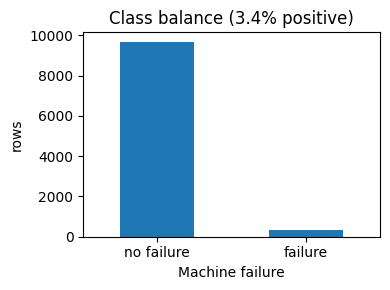

In [4]:
counts = df[TARGET].value_counts()
print(counts, "\nPositive rate:", round(df[TARGET].mean(), 4))
fig, ax = plt.subplots(figsize=(4, 3))
counts.plot.bar(ax=ax)
ax.set(xticklabels=["no failure", "failure"], ylabel="rows", title="Class balance (3.4% positive)")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 4. Sensor distributions by class

Failures are not spread uniformly: they concentrate at high tool wear, high torque and extreme rotational speeds - consistent with the physical failure modes documented by UCI.

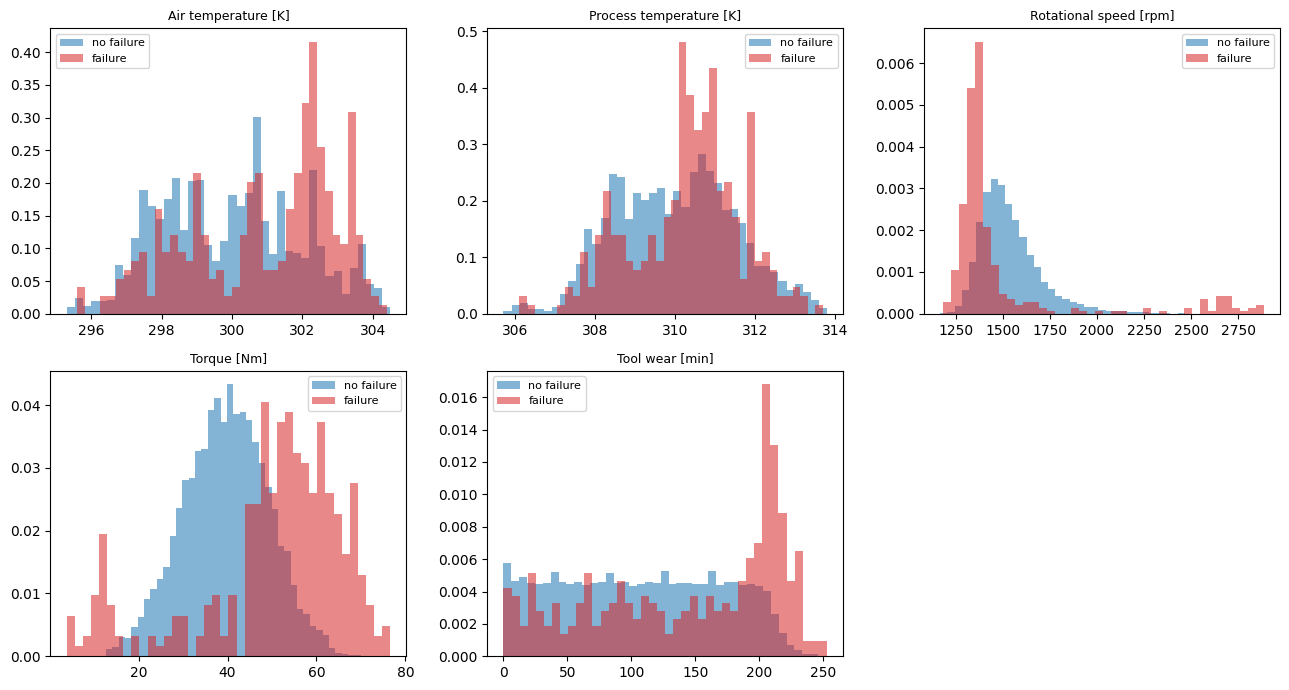

In [5]:
num_cols = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), num_cols):
    for label, grp, color in [(0, "no failure", "tab:blue"), (1, "failure", "tab:red")]:
        ax.hist(df.loc[df[TARGET] == label, c], bins=40, alpha=0.55, label=grp, color=color, density=True)
    ax.set_title(c, fontsize=9); ax.legend(fontsize=8)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

## 5. Correlations

Air and process temperature move together (correlation ~0.88) - neither alone is the failure signal; their **difference** is (see section 8). Torque and rotational speed are strongly anti-correlated.

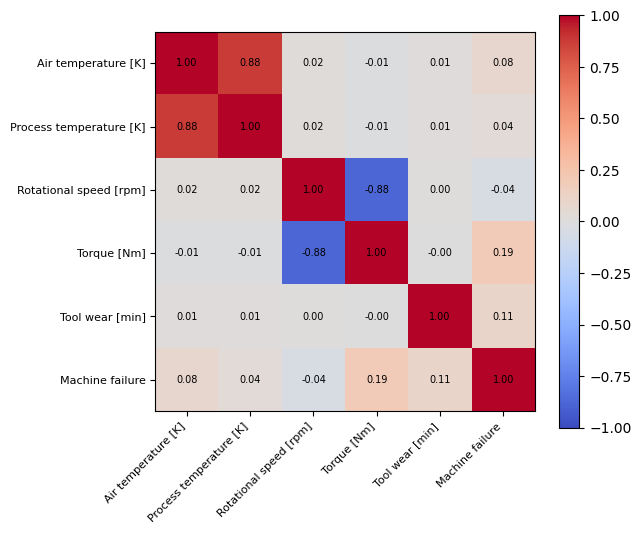

In [6]:
corr = df[num_cols + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set(xticks=range(len(corr)), yticks=range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(corr.columns, fontsize=8)
for (i, j), v in np.ndenumerate(corr.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im); plt.tight_layout(); plt.show()

## 6. Leakage check: the failure-mode flags

TWF/HDF/PWF/OSF/RNF are recorded **when** a failure occurs - they are never 1 on a healthy run. Using them as features would be target leakage: the model would learn the label, not the physics. We exclude them from the feature set and use them only for error analysis.

In [7]:
for c in LEAKAGE_COLS:
    tab = pd.crosstab(df[c], df[TARGET])
    print(f"{c}: 1s only occur when Machine failure = 1 ->", bool((df.loc[df[c] == 1, TARGET] == 1).all()))
print("\nFailure rows by mode:")
print(df.loc[df[TARGET] == 1, LEAKAGE_COLS].sum())

TWF: 1s only occur when Machine failure = 1 -> True
HDF: 1s only occur when Machine failure = 1 -> True
PWF: 1s only occur when Machine failure = 1 -> True
OSF: 1s only occur when Machine failure = 1 -> True
RNF: 1s only occur when Machine failure = 1 -> False

Failure rows by mode:
TWF     46
HDF    115
PWF     95
OSF     98
RNF      1
dtype: int64


## 7. Outliers (IQR rule)

No impossible values; the "outliers" flagged by the IQR rule (very high torque, very low/high speed, long tool wear) are exactly the stressed operating points where failures happen, so they are **kept**, not clipped.

In [8]:
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    n_out_fail = int((((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)) & (df[TARGET] == 1)).sum())
    print(f"{c:25s} IQR outliers: {n_out:4d}  (of which failures: {n_out_fail})")

Air temperature [K]       IQR outliers:    0  (of which failures: 0)
Process temperature [K]   IQR outliers:    0  (of which failures: 0)
Rotational speed [rpm]    IQR outliers:  418  (of which failures: 35)
Torque [Nm]               IQR outliers:   69  (of which failures: 62)
Tool wear [min]           IQR outliers:    0  (of which failures: 0)


## 8. Engineered features

Two derived features match the physical failure definitions:

* **temp_diff** = process - air temperature. Heat-dissipation failures (HDF) occur when the process can no longer shed heat, i.e. at a *small* temperature difference for a given speed.
* **power_w** = torque x angular velocity (W). Power failures (PWF) are defined exactly on mechanical power being outside ~3.5-9 kW.

Both separate the classes visibly better than the raw columns alone.

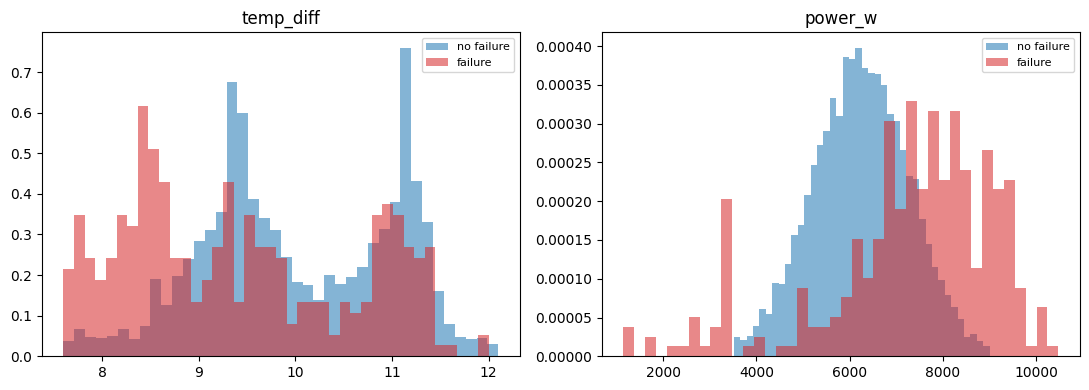

In [9]:
dfe = add_engineered_features(df)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, c in zip(axes, ["temp_diff", "power_w"]):
    for label, grp, color in [(0, "no failure", "tab:blue"), (1, "failure", "tab:red")]:
        ax.hist(dfe.loc[dfe[TARGET] == label, c], bins=40, alpha=0.55, label=grp, color=color, density=True)
    ax.set_title(c); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Conclusions carried into modelling

1. No missing values or duplicates; outliers are real stressed states -> kept.
2. Strong class imbalance (3.4%) -> stratified split, `class_weight`/`scale_pos_weight`, PR-AUC and recall-oriented metrics instead of accuracy.
3. Failure-mode flags leak the target -> excluded from features, used only in error analysis.
4. Engineered `temp_diff` and `power_w` encode the documented failure physics.
5. Failures follow threshold-like patterns -> tree ensembles (Random Forest, XGBoost, LightGBM) are expected to beat a linear model; Logistic Regression is kept as the interpretable baseline.